# Sulfur recovery: Claus train and SCOT tail-gas treating

`difflow_refinery.sulfur` (#472) models a modified-Claus sulfur recovery unit:
- an adiabatic-equilibrium furnace;
- a waste-heat boiler and sulfur condensers, using allotrope speciation and the measured vapour pressure of Ferreira & Lobo (2011);
- catalytic converters;
- air-demand control to a tail-gas ratio H2S = 2 SO2;
- a SCOT-type tail-gas unit, whose acid gas is recycled to the furnace.

Everything is differentiable.

In [1]:
import jax, jax.numpy as jnp, numpy as np
jax.config.update("jax_enable_x64", True)
import matplotlib.pyplot as plt
from difflow import make_stream, GibbsReactor, GibbsReactorParams
from difflow_refinery import thermochemistry as tc
from difflow_refinery import sulfur as su
from difflow_refinery.treating import TrayParams

## The Gamson-Elkins curve

This is the equilibrium conversion of a stoichiometric H2S/SO2 mixture in air at 1 atm, with all sulfur in the vapour.
- In the thermal region (above ~1100 K), conversion rises with temperature.
- In the catalytic region, conversion rises as temperature falls.
- The minimum sits near 811 K (Kohl & Nielsen).

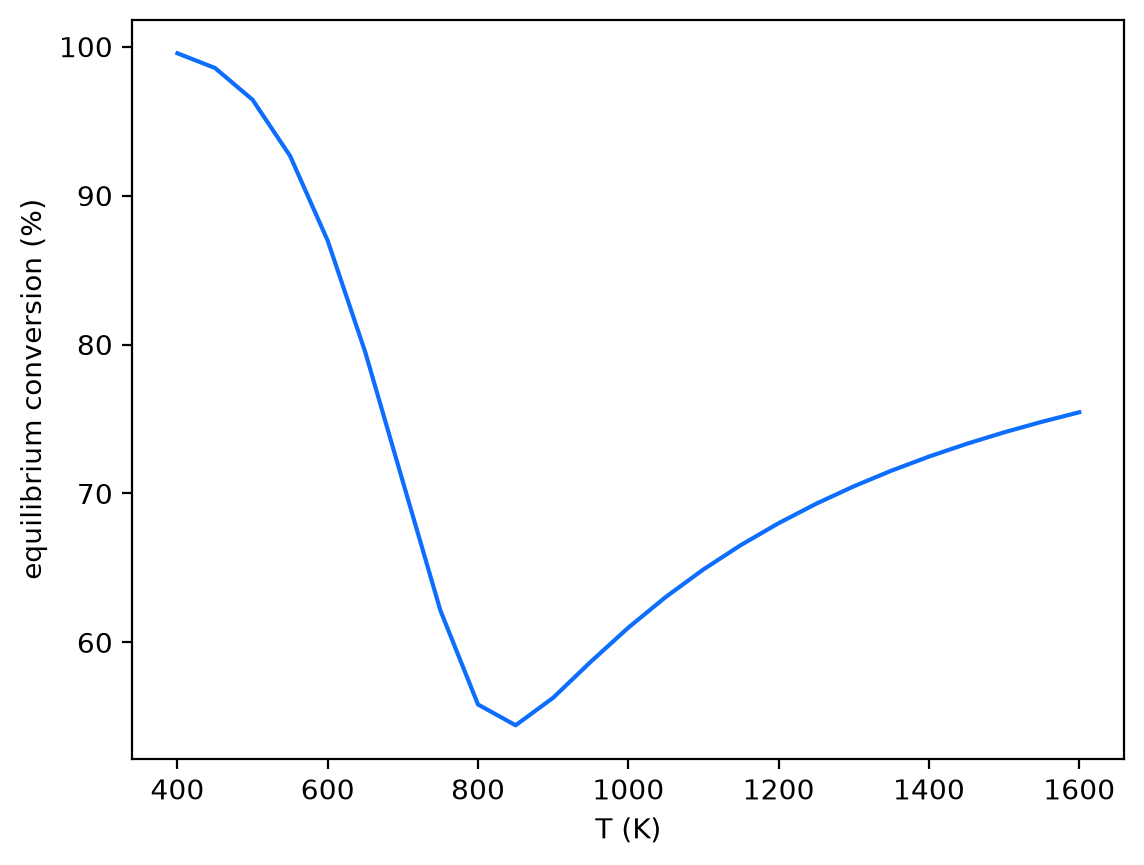

In [2]:
names = ["hydrogen_sulfide", "sulfur_dioxide", *su.vapor.SULFUR_SPECIES, "water", "nitrogen"]
th = tc.IdealGasSet(names, cp_basis="wide")
feed = make_stream({"hydrogen_sulfide": 2/3, "sulfur_dioxide": 1/3, "water": 1/3,
                    "nitrogen": 0.5 * (1 - su.AIR_O2) / su.AIR_O2}, T=500.0, P=101325.0)
Ts = np.arange(400.0, 1601.0, 50.0)
X = []
for T in Ts:
    o, _ = GibbsReactor(GibbsReactorParams(thermo=th, T_out=T))(feed)
    X.append(1 - float(o["F_hydrogen_sulfide"] + o["F_sulfur_dioxide"]))
plt.plot(Ts, 100 * np.array(X)); plt.xlabel("T (K)"); plt.ylabel("equilibrium conversion (%)");

## A three-bed Claus train under air-demand control

The feed is a refinery acid gas: 90% H2S, with CO2, water and a little methane. Bed and condenser temperatures fall inside Kohl & Nielsen's operating ranges.

In [3]:
acid = make_stream({"hydrogen_sulfide": 90.0, "carbon_dioxide": 5.0, "water": 4.0, "methane": 1.0},
                   T=323.15, P=1.6e5)
beds = (su.ConverterParams(523.15, hydrolysis=(0.9, 0.7)), su.ConverterParams(483.15),
        su.ConverterParams(473.15))
claus = su.ClausParams(converters=beds, T_condensers=(443.15, 438.15, 433.15, 413.15), T_air=473.15)
air, r = jax.jit(lambda g: su.solve_air(g, claus))(acid)
print(f"air {float(air):.2f} mol/s, furnace {float(r['T_furnace']):.0f} K, recovery {100*float(r['recovery']):.2f} %")
print("sulfur by condenser (mol S/s):", np.round(np.asarray(r["sulfur_by_condenser"]), 3))
print("bed outlet T (K):", [round(float(b["T_out"]), 1) for b in r["bed"]],
      " margin above dew point (K):", [round(float(b["dew_margin"]), 1) for b in r["bed"]])
print(f"steam: WHB {float(r['steam_whb']):.2f} kg/s, condensers {float(r['steam_condensers']):.2f} kg/s")

air 192.62 mol/s, furnace 1534 K, recovery 98.56 %
sulfur by condenser (mol S/s): [ 0.    65.644 16.528  5.203  1.328]
bed outlet T (K): [584.9, 503.8, 477.2]  margin above dew point (K): [67.1, 17.3, 22.8]
steam: WHB 5.77 kg/s, condensers 2.08 kg/s


These are equilibrium recoveries, so they are an upper bound. EPA AP-42 gives 95-97.5% for three beds in practice.

## The closed SRU: two beds plus the TGTU

The tail-gas unit works in four steps:
1. It hydrogenates SO2 and sulfur vapour to H2S.
2. A quench removes most of the water.
3. A selective MDEA absorber takes up the H2S and lets most of the CO2 slip.
4. The absorbed acid gas goes back to the furnace.

The recycle is a tear stream, solved with an implicit derivative.

In [4]:
tgtu = su.TGTUParams(tray=TrayParams(area=200.0, k_G=1e-5, k_L=1e-4), L=30.0, n_stages=12, P_absorber=1.2e5)
claus2 = su.ClausParams(converters=beds[:2], T_condensers=(443.15, 438.15, 413.15), T_air=473.15)
sru_fn = jax.jit(lambda g: su.solve_sru(g, claus2, tgtu))
sru = sru_fn(acid)
print(f"overall recovery {100*float(sru['recovery']):.3f} %, SO2 {float(sru['SO2_emitted_kg_h']):.2f} kg/h")
print("recycle H2S, CO2, H2O (mol/s):", np.round(np.asarray(sru["recycle"]), 3), " loop gain", round(float(sru["gain"]), 3))

overall recovery 99.987 %, SO2 2.65 kg/h
recycle H2S, CO2, H2O (mol/s): [2.319 0.564 0.2  ]  loop gain 0.084


## Sensitivity of SO2 emissions to the feed H2S

In [5]:
g = jax.jit(jax.grad(lambda h: su.solve_sru(dict(acid, F_hydrogen_sulfide=h), claus2, tgtu)["SO2_emitted"]))(90.0)
print(f"d(SO2 emitted)/d(H2S fed) = {float(g):.3e} mol/mol")

d(SO2 emitted)/d(H2S fed) = 3.582e-04 mol/mol
